# Module 3: Fracture Position Detection — YOLO26


**Pipeline stages:**
1. Install dependencies --> No longer doing that, setup your env in your terminal / tmp cells then delete them
2. Download all 3 datasets via Roboflow
3. Imports & configuration
4. Create merged dataset structure
5. Copy & merge all datasets
6. Dataset summary
7. Write `data.yaml`
8. Train YOLO26
9. Evaluate on test set
10. Inference & visualize bounding boxes
11. Batch inference
12. Export model

---
## Check Cuda Compatability

In [27]:
import os
# I need this to run torch on my computer, comment it according to your GPU, please do not delete, comment ~Omar
os.environ["HSA_OVERRIDE_GFX_VERSION"] = "11.0.0"

In [28]:
import torch
print(torch.__version__)
print("CUDA available:", torch.cuda.is_available())
import gc
gc.collect()
if torch.cuda.is_available():
    dev = torch.cuda.get_device_properties(0)
    torch.cuda.empty_cache()
    print(f"GPU: {dev.name}")
    print(f"VRAM: {dev.total_memory / 1024**3:.1f} GB")

2.5.1+rocm6.1
CUDA available: True
GPU: AMD Radeon Graphics
VRAM: 16.0 GB


## Load Dataset

In [29]:
from pathlib import Path

notebook_folderPath = Path().absolute()

MERGED_DIR = notebook_folderPath / "input" / "Base Dataset"

print(f"MERGED_DIR: {MERGED_DIR}")

MERGED_DIR: /home/omarriad/Documents/10th Sem/DMET 1067 - Deep Learning in Computer Vision/Project Milestone 2/Model Fine-tuning/Models Workspaces/X-Ray Bounding Box Extraction/input/Base Dataset


## Imports & Configuration

In [30]:
import os
import csv
import yaml
from torch import cuda
import cv2
import numpy as np
import matplotlib.patches as patches
import matplotlib.pyplot as plt
from ultralytics import YOLO

# Output configuration
WORKSPACE_DIR = notebook_folderPath
RUN_NAME = "Detectron2 + Faster R-CNN + ResNet152 backbone Tuesday Fajr"


# Hyperparameters and training configuration
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
PIN_MEMORY = cuda.is_available()


EARLY_STOPPING_PATIENCE = 12
BATCH_SIZE = 4          
NUM_WORKERS = 4   
EPOCHS = 75
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 1e-4

MIN_SIZE = 800
MAX_SIZE = 1600 
MODEL_SAVE_PATH = WORKSPACE_DIR/ "output" / "final_model" /"best_model.pth"

os.makedirs(MODEL_SAVE_PATH.parent, exist_ok=True)


## Prepare Dataset

In [31]:
import os
import random
import shutil
from pathlib import Path

def split_bg_from_non_bg(dataset_dir="/workspace/Merged_Fracture", split="train", keep_bg_count=500, random_seed=42):
    images_dir = Path(dataset_dir) / split / "images"
    labels_dir = Path(dataset_dir) / split / "labels"
    
    # Create a backup folder for the excess backgrounds
    backup_img_dir = Path(dataset_dir) / f"{split}_excess_bg" / "images"
    backup_lbl_dir = Path(dataset_dir) / f"{split}_excess_bg" / "labels"
    backup_img_dir.mkdir(parents=True, exist_ok=True)
    backup_lbl_dir.mkdir(parents=True, exist_ok=True)

    background_images = []
    
    # Find all images
    for img_path in images_dir.glob("*.*"):
        if img_path.suffix.lower() not in [".jpg", ".png", ".jpeg"]: continue
            
        lbl_path = labels_dir / (img_path.stem + ".txt")
        
        # If label doesn't exist or is empty, it's a background!
        if not lbl_path.exists() or lbl_path.stat().st_size == 0:
            background_images.append((img_path, lbl_path))

    print(f"Found {len(background_images)} background images in the '{split}' set.")
    
    if len(background_images) <= keep_bg_count:
        print("Dataset is already balanced!")
        return

    # Shuffle and pick the ones to move
    random.seed(random_seed)
    random.shuffle(background_images)
    excess_bgs = background_images[keep_bg_count:]
    
    print(f"Moving {len(excess_bgs)} excess background images out of the training set...")
    
    for img_path, lbl_path in excess_bgs:
        shutil.move(str(img_path), str(backup_img_dir / img_path.name))
        if lbl_path.exists():
            shutil.move(str(lbl_path), str(backup_lbl_dir / lbl_path.name))
            
    print(f"✅ Done! Your '{split}' set is now balanced.")

# Run the balancer!
split_bg_from_non_bg(dataset_dir=MERGED_DIR, split="train", keep_bg_count=0)
split_bg_from_non_bg(dataset_dir=MERGED_DIR, split="val", keep_bg_count=0)
split_bg_from_non_bg(dataset_dir=MERGED_DIR, split="test", keep_bg_count=0)

Found 0 background images in the 'train' set.
Dataset is already balanced!
Found 0 background images in the 'val' set.
Dataset is already balanced!
Found 0 background images in the 'test' set.
Dataset is already balanced!


### Split dataset into 70/20/10

In [32]:
def balance_splits(dataset_dir="/workspace/Merged_Fracture", output_dir=None, splits=["train", "val", "test"], split_ratio = [0.7, 0.2, 0.1], bg_ratio=0.3, random_seed=42):
    if len(splits) != len(split_ratio):
        raise ValueError("Length of splits and split_ratio must be the same.")
    
    if output_dir is None:
        raise ValueError("Please provide an output directory to save the balanced dataset.")
    
    total_non_bg = len(list((dataset_dir / "train" / "labels").glob("*.txt"))) + len(list((dataset_dir / "val" / "labels").glob("*.txt"))) + len(list((dataset_dir / "test" / "labels").glob("*.txt")))
    total_bg = len(list((dataset_dir / "train_excess_bg" / "images").glob("*.*"))) + len(list((dataset_dir / "val_excess_bg" / "images").glob("*.*"))) + len(list((dataset_dir / "test_excess_bg" / "images").glob("*.*")))
    print(f"Total non-background images across all splits: {total_non_bg}")
    print(f"Total background images across all splits: {total_bg}")
    
    target_train_non_bg = total_non_bg * split_ratio[0]
    target_val_non_bg = total_non_bg * split_ratio[1]
    target_test_non_bg = total_non_bg * split_ratio[2]

    target_train_bg = round(target_train_non_bg * bg_ratio / (1 - bg_ratio))
    target_val_bg = round(target_val_non_bg * bg_ratio / (1 - bg_ratio))
    target_test_bg = round(target_test_non_bg * bg_ratio / (1 - bg_ratio))

    if target_train_bg + target_val_bg + target_test_bg > total_bg:
        raise ValueError("Not enough background images to meet the desired bg_ratio. Please adjust the bg_ratio or provide more background images.")

    total_train = total_non_bg * split_ratio[0] + target_train_bg
    total_val = total_non_bg * split_ratio[1] + target_val_bg
    total_test = total_non_bg * split_ratio[2] + target_test_bg

    print(f"Target Dataset and Background Counts:")
    print(f"  Train: {target_train_bg} bg/{int(total_train)} total")
    print(f"  Val: {target_val_bg} bg/{int(total_val)} total")
    print(f"  Test: {target_test_bg} bg/{int(total_test)} total")

    print("\nBalancing splits...")

    all_non_bg_images_with_labels = []
    for split in splits:
        split_images_dir = dataset_dir / split / "images"
        for image_path in split_images_dir.glob("*.*"):
            label_path = dataset_dir / split / "labels" / (image_path.stem + ".txt")
            if not label_path.exists():
                raise ValueError(f"Label file {label_path} does not exist for image {image_path}.")
            all_non_bg_images_with_labels.append((image_path, label_path))

    all_bg_images_with_labels = []
    for split in splits:
        excess_bg_images_dir = dataset_dir / f"{split}_excess_bg" / "images"
        excess_bg_labels_dir = dataset_dir / f"{split}_excess_bg" / "labels"
        for image_path in excess_bg_images_dir.glob("*.*"):
            label_path = excess_bg_labels_dir / (image_path.stem + ".txt")
            if not label_path.exists():
                raise ValueError(f"Label file {label_path} does not exist for background image {image_path}.")
            all_bg_images_with_labels.append((image_path, label_path))

    random.seed(random_seed)
    random.shuffle(all_non_bg_images_with_labels)
    random.shuffle(all_bg_images_with_labels)

    for tuple in [(target_train_non_bg, target_train_bg, "train"), (target_val_non_bg, target_val_bg, "val"), (target_test_non_bg, target_test_bg, "test")]:
        #print(f"Processing split '{tuple[2]}' with target {int(tuple[0])} non-bg and {tuple[1]} bg images...")
        images = []
        images.extend(all_non_bg_images_with_labels[:int(tuple[0])])
        all_non_bg_images_with_labels = all_non_bg_images_with_labels[int(tuple[0]):]
        images.extend(all_bg_images_with_labels[:int(tuple[1])])
        all_bg_images_with_labels = all_bg_images_with_labels[int(tuple[1]):]

        #shuffle and copy to output dir
        random.shuffle(images)
        for img_path, lbl_path in images:
            dest_img_path = Path(output_dir) / tuple[2] / "images" / img_path.name
            dest_lbl_path = Path(output_dir) / tuple[2] / "labels" / lbl_path.name
            dest_img_path.parent.mkdir(parents=True, exist_ok=True)
            dest_lbl_path.parent.mkdir(parents=True, exist_ok=True)
            shutil.copy(str(img_path), str(dest_img_path))
            shutil.copy(str(lbl_path), str(dest_lbl_path))


CLEANED_DATASET_DIR = MERGED_DIR.parent / "Balanced_Dataset"
os.makedirs(CLEANED_DATASET_DIR, exist_ok=True)

balance_splits(dataset_dir=MERGED_DIR, output_dir=CLEANED_DATASET_DIR, splits=["train", "val", "test"], split_ratio = [0.7, 0.2, 0.1], bg_ratio=0.3, random_seed=42)

Total non-background images across all splits: 4351
Total background images across all splits: 12321
Target Dataset and Background Counts:
  Train: 1305 bg/4350 total
  Val: 373 bg/1243 total
  Test: 186 bg/621 total

Balancing splits...


### Validate Existing Merged Dataset

No source datasets are copied or merged in this notebook.

In [33]:
def find_val_split(root: Path) -> str:
    if (root / "val" / "images").exists():
        return "val"
    if (root / "valid" / "images").exists():
        return "valid"
    return "val"

def count_images(folder: Path) -> int:
    return len(list(folder.glob("*.jpg"))) + len(list(folder.glob("*.png")))

root = Path(CLEANED_DATASET_DIR)
val_split = find_val_split(root)

splits = ["train", val_split, "test"]
print("=== Validating merged dataset ===")
total = 0
for split in splits:
    img_dir = root / split / "images"
    lbl_dir = root / split / "labels"

    if not img_dir.exists():
        print(f"  Missing: {img_dir}")
        continue
    if not lbl_dir.exists():
        print(f"  Missing: {lbl_dir}")
        continue

    n = count_images(img_dir)
    total += n
    print(f"  {split:<5}: {n:>5} images")

if total == 0:
    raise ValueError(
        "No images found in merged dataset. "
        "Expected folders like train/images, val(or valid)/images, test/images."
    )

print(f"\nMerged dataset looks ready. Total images found: {total}")

=== Validating merged dataset ===
  train:  4350 images
  val  :  1243 images
  test :   621 images

Merged dataset looks ready. Total images found: 6214


### Dataset Summary

Merged Dataset Summary
-----------------------------------
  Train :  4350 images
  Val  :  1243 images
  Test  :   621 images
-----------------------------------
  Total :  6214 images


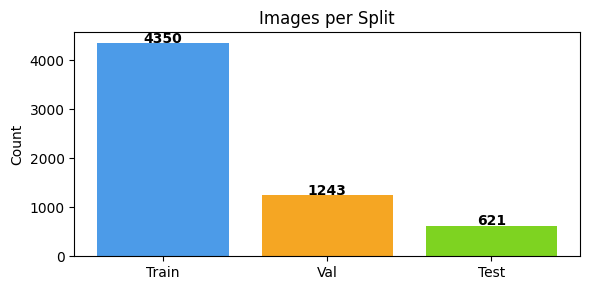

In [34]:
def resolve_val_split(root: Path) -> str:
    if (root / "val" / "images").exists():
        return "val"
    if (root / "valid" / "images").exists():
        return "valid"
    return "val"

def count_split(split):
    img_dir = Path(CLEANED_DATASET_DIR) / split / "images"
    if not img_dir.exists():
        return 0
    return len(list(img_dir.glob("*.jpg"))) + len(list(img_dir.glob("*.png")))

val_split = resolve_val_split(Path(CLEANED_DATASET_DIR))

train_n = count_split("train")
val_n   = count_split(val_split)
test_n  = count_split("test")
total   = train_n + val_n + test_n

print("Merged Dataset Summary")
print("-" * 35)
print(f"  Train : {train_n:>5} images")
print(f"  {val_split.capitalize():<5}: {val_n:>5} images")
print(f"  Test  : {test_n:>5} images")
print("-" * 35)
print(f"  Total : {total:>5} images")

fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(["Train", val_split.capitalize(), "Test"], [train_n, val_n, test_n],
       color=["#4C9BE8", "#F5A623", "#7ED321"])
ax.set_title("Images per Split")
ax.set_ylabel("Count")
for i, v in enumerate([train_n, val_n, test_n]):
    ax.text(i, v + 10, str(v), ha="center", fontweight="bold")
plt.tight_layout()
plt.show()

In [35]:
def write_yaml():
    root = Path(CLEANED_DATASET_DIR)
    val_split = "val" if (root / "val" / "images").exists() else "valid"
    config = {
        "path": CLEANED_DATASET_DIR,
        "train": "train/images",
        "val": f"{val_split}/images",
        "test": "test/images",
        "nc": 1,
        "names": ["fracture"],
        "image_split": {
            "train": train_n,
            "val": val_n,
            "test": test_n
        }
    }
    yaml_path = os.path.join(CLEANED_DATASET_DIR, "data.yaml")
    with open(yaml_path, "w") as f:
        yaml.dump(config, f, default_flow_style=False, sort_keys=False)
    print(f"data.yaml written to:\n   {yaml_path}")
    print("\nContents:")
    print("-" * 30)
    with open(yaml_path) as f:
        print(f.read())
    return yaml_path

YAML_PATH = write_yaml()

data.yaml written to:
   /home/omarriad/Documents/10th Sem/DMET 1067 - Deep Learning in Computer Vision/Project Milestone 2/Model Fine-tuning/Models Workspaces/X-Ray Bounding Box Extraction/input/Balanced_Dataset/data.yaml

Contents:
------------------------------
path: !!python/object/apply:pathlib.PosixPath
- /
- home
- omarriad
- Documents
- 10th Sem
- DMET 1067 - Deep Learning in Computer Vision
- Project Milestone 2
- Model Fine-tuning
- Models Workspaces
- X-Ray Bounding Box Extraction
- input
- Balanced_Dataset
train: train/images
val: val/images
test: test/images
nc: 1
names:
- fracture
image_split:
  train: 4350
  val: 1243
  test: 621



### Convert Labels from YOLO to COCO JSON

In [36]:
import json
import cv2

def yolo_to_coco(images_dir, labels_dir, output_json, categories):
    images_dir = Path(images_dir)
    labels_dir = Path(labels_dir)
    
    coco = {
        "images": [],
        "annotations": [],
        "categories": categories
    }
    
    ann_id = 0
    img_id = 0
    
    for img_path in sorted(images_dir.glob("*.*")):
        if img_path.suffix.lower() not in [".jpg", ".jpeg", ".png"]:
            continue
        
        img = cv2.imread(str(img_path))
        if img is None:
            continue
        h, w = img.shape[:2]
        
        coco["images"].append({
            "id": img_id,
            "file_name": img_path.name,
            "height": h,
            "width": w
        })
        
        label_path = labels_dir / (img_path.stem + ".txt")
        if label_path.exists():
            with open(label_path) as f:
                for line in f.readlines():
                    line = line.strip()
                    if not line:
                        continue
                    cls, cx, cy, bw, bh = map(float, line.split())
                    
                    # Convert YOLO normalized to absolute COCO format
                    x1 = (cx - bw / 2) * w
                    y1 = (cy - bh / 2) * h
                    abs_w = bw * w
                    abs_h = bh * h
                    
                    coco["annotations"].append({
                        "id": ann_id,
                        "image_id": img_id,
                        "category_id": int(cls),
                        "bbox": [x1, y1, abs_w, abs_h],  # COCO: [x, y, w, h]
                        "area": abs_w * abs_h,
                        "iscrowd": 0
                    })
                    ann_id += 1
        
        img_id += 1
    
    with open(output_json, "w") as f:
        json.dump(coco, f)
    
    print(f"Saved {output_json}: {img_id} images, {ann_id} annotations")

categories = [{"id": 0, "name": "fracture"}]

for split in ["train", "val", "test"]:
    yolo_to_coco(
        images_dir=f"{CLEANED_DATASET_DIR}/{split}/images",
        labels_dir=f"{CLEANED_DATASET_DIR}/{split}/labels",
        output_json=f"{CLEANED_DATASET_DIR}/{split}/annotations.json",
        categories=categories
    )

Saved /home/omarriad/Documents/10th Sem/DMET 1067 - Deep Learning in Computer Vision/Project Milestone 2/Model Fine-tuning/Models Workspaces/X-Ray Bounding Box Extraction/input/Balanced_Dataset/train/annotations.json: 4350 images, 4039 annotations
Saved /home/omarriad/Documents/10th Sem/DMET 1067 - Deep Learning in Computer Vision/Project Milestone 2/Model Fine-tuning/Models Workspaces/X-Ray Bounding Box Extraction/input/Balanced_Dataset/val/annotations.json: 1243 images, 1173 annotations
Saved /home/omarriad/Documents/10th Sem/DMET 1067 - Deep Learning in Computer Vision/Project Milestone 2/Model Fine-tuning/Models Workspaces/X-Ray Bounding Box Extraction/input/Balanced_Dataset/test/annotations.json: 621 images, 573 annotations


## The Model

In [37]:
# tests detectron2 installation and prints version
import detectron2
print(detectron2.__version__)

0.6


In [38]:
import os
import torch
from pathlib import Path
from detectron2.data.datasets import register_coco_instances
from detectron2.engine import DefaultTrainer
from detectron2.config import get_cfg
from detectron2 import model_zoo
from detectron2.evaluation import COCOEvaluator
from detectron2.engine.hooks import BestCheckpointer



In [39]:
from detectron2.engine import HookBase
import detectron2.utils.comm as comm

class EarlyStoppingHook(HookBase):
    def __init__(self, eval_period, patience, metric="bbox/AP"):
        self._eval_period = eval_period
        self._patience = patience
        self._metric = metric
        self._best = 0.0
        self._no_improve = 0

    def after_step(self):
        next_iter = self.trainer.iter + 1
        if next_iter % self._eval_period == 0:
            comm.synchronize()
            metrics = self.trainer.storage.latest()
            if self._metric in metrics:
                val = metrics[self._metric][0]
                if val > self._best:
                    self._best = val
                    self._no_improve = 0
                    print(f"[EarlyStopping] Improved {self._metric}: {val:.4f}")
                else:
                    self._no_improve += 1
                    print(f"[EarlyStopping] No improvement {self._no_improve}/{self._patience}")
                    if self._no_improve >= self._patience:
                        print(f"[EarlyStopping] Stopping at iter {next_iter}")
                        raise StopIteration

In [ ]:
OUTPUT_DIR    = WORKSPACE_DIR / "output" / "final_model"


# Map epochs to iterations
TRAIN_IMAGES    = train_n
IMS_PER_BATCH   = BATCH_SIZE if BATCH_SIZE <= 4 else 4
ITERS_PER_EPOCH = TRAIN_IMAGES // IMS_PER_BATCH      
MAX_ITER        = ITERS_PER_EPOCH * EPOCHS         
EVAL_PERIOD     = ITERS_PER_EPOCH                   
CHECKPOINT_FREQ = ITERS_PER_EPOCH * 5              
LR_DECAY_STEPS  = (int(MAX_ITER * 0.7), int(MAX_ITER * 0.9))

os.makedirs(OUTPUT_DIR, exist_ok=True)

# Register datasets
for split in ["train", "val", "test"]:
    register_coco_instances(
        f"fracture_{split}",
        {},
        f"{CLEANED_DATASET_DIR}/{split}/annotations.json",
        f"{CLEANED_DATASET_DIR}/{split}/images"
    )

class FractureTrainer(DefaultTrainer):
    @classmethod
    def build_evaluator(cls, cfg, dataset_name, output_folder=None):
        return COCOEvaluator(dataset_name, cfg, False, output_dir=str(OUTPUT_DIR))

    def build_hooks(self):
        hooks = super().build_hooks()
        
        # Save best model
        hooks.insert(-1, BestCheckpointer(
            eval_period=EVAL_PERIOD,
            checkpointer=self.checkpointer,
            val_metric="bbox/AP",
            mode="max"
        ))
        
        # Early stopping
        hooks.append(EarlyStoppingHook(
            eval_period=EVAL_PERIOD,
            patience=EARLY_STOPPING_PATIENCE,
            metric="bbox/AP"
        ))
        
        return hooks

# Config
cfg = get_cfg()
cfg.merge_from_file(model_zoo.get_config_file(
    "COCO-Detection/faster_rcnn_R_101_FPN_3x.yaml"
))

cfg.DATASETS.TRAIN                     = ("fracture_train",)
cfg.DATASETS.TEST                      = ("fracture_val",)

cfg.DATALOADER.NUM_WORKERS             = NUM_WORKERS
cfg.DATALOADER.PIN_MEMORY              = PIN_MEMORY

cfg.MODEL.WEIGHTS                      = model_zoo.get_checkpoint_url(
    "COCO-Detection/faster_rcnn_R_101_FPN_3x.yaml"
)
cfg.MODEL.DEVICE                       = DEVICE
cfg.MODEL.ROI_HEADS.NUM_CLASSES        = 1
cfg.MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE = 128
cfg.INPUT.MIN_SIZE_TRAIN               = (MIN_SIZE,)
cfg.INPUT.MAX_SIZE_TRAIN               = MAX_SIZE
cfg.INPUT.MIN_SIZE_TEST                = MIN_SIZE
cfg.INPUT.MAX_SIZE_TEST                = MAX_SIZE

cfg.SOLVER.IMS_PER_BATCH               = IMS_PER_BATCH
cfg.SOLVER.BASE_LR                     = LEARNING_RATE
cfg.SOLVER.WEIGHT_DECAY                = WEIGHT_DECAY
cfg.SOLVER.MAX_ITER                    = MAX_ITER
cfg.SOLVER.STEPS                       = LR_DECAY_STEPS
cfg.SOLVER.GAMMA                       = 0.1
cfg.SOLVER.WARMUP_ITERS                = 500
cfg.SOLVER.CHECKPOINT_PERIOD           = CHECKPOINT_FREQ

cfg.TEST.EVAL_PERIOD                   = EVAL_PERIOD

cfg.OUTPUT_DIR                         = str(OUTPUT_DIR)

print(f"Device:         {DEVICE}")
print(f"IMS_PER_BATCH:  {IMS_PER_BATCH}")
print(f"Iters/epoch:    {ITERS_PER_EPOCH}")
print(f"Total iters:    {MAX_ITER}  (~{EPOCHS} epochs)")
print(f"Eval every:     {EVAL_PERIOD} iters (every epoch)")
print(f"LR decay at:    {LR_DECAY_STEPS}")
print(f"Output:         {OUTPUT_DIR}")


trainer = FractureTrainer(cfg)
trainer.resume_or_load(resume=False)

try:
    trainer.train()
except StopIteration:
    print("Training stopped early.")

Device:         cuda
IMS_PER_BATCH:  4
Iters/epoch:    1087
Total iters:    81525  (~75 epochs)
Eval every:     1087 iters (every epoch)
LR decay at:    (57067, 73372)
Output:         /home/omarriad/Documents/10th Sem/DMET 1067 - Deep Learning in Computer Vision/Project Milestone 2/Model Fine-tuning/Models Workspaces/X-Ray Bounding Box Extraction/output/final_model
[04/28 03:01:59 d2.engine.defaults]: Model:
GeneralizedRCNN(
  (backbone): FPN(
    (fpn_lateral2): Conv2d(256, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output2): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral3): Conv2d(512, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output3): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral4): Conv2d(1024, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output4): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral5): Conv2d(2048, 256, kernel_size=(1, 1), stride=(1, 1))
 

Skip loading parameter 'roi_heads.box_predictor.cls_score.weight' to the model due to incompatible shapes: (81, 1024) in the checkpoint but (2, 1024) in the model! You might want to double check if this is expected.
Skip loading parameter 'roi_heads.box_predictor.cls_score.bias' to the model due to incompatible shapes: (81,) in the checkpoint but (2,) in the model! You might want to double check if this is expected.
Skip loading parameter 'roi_heads.box_predictor.bbox_pred.weight' to the model due to incompatible shapes: (320, 1024) in the checkpoint but (4, 1024) in the model! You might want to double check if this is expected.
Skip loading parameter 'roi_heads.box_predictor.bbox_pred.bias' to the model due to incompatible shapes: (320,) in the checkpoint but (4,) in the model! You might want to double check if this is expected.
Some model parameters or buffers are not found in the checkpoint:
roi_heads.box_predictor.bbox_pred.{bias, weight}
roi_heads.box_predictor.cls_score.{bias, we

[04/28 03:01:59 d2.engine.train_loop]: Starting training from iteration 0
